# P12 — A `anotacaoSubset`: marcadores, composição e estímulo

**Rótulos.** A `anotacaoSubset` das 30.933 CD4 limpas, em
`dataReseq/P11_naive_memoria_subset/anotacao_subset`:
- estados de Treg do P10;
- naive e memória do P11;
- ativada, ativada (Th17) e citotóxica com a `anotacao`.

**Seções.**
1. A UMAP das CD4 (P09) pela `anotacaoSubset` e pelo estímulo.
2. O dotplot dos marcadores principais de cada tipo (painel curado).
3. Os 5 genes diferenciais de cada tipo (Wilcoxon, um contra todos).
4. A composição por biblioteca.
5. O teste de composição, pelo método do P17 da 1ª rodada (`forest_composicao`):
   - estímulo: `CLR ~ estímulo + paciente + %MT`;
   - grupo clínico: um ponto por paciente.

**Limite.** 7 pacientes e 14 bibliotecas; MB e NP com um paciente cada. Só o contraste pareado
ML × NS (n = 7) admite inferência; os grupos clínicos são exploratórios.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import display
from scipy.stats import binomtest

from functions import config, fmt as F, io, plotting
from functions import anotacao as an
from functions import composicao as CP
from functions import composicao_sc as CS
from functions import forest_composicao as FR
from functions import pipeline as pl
from functions import subset as SB
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
sc.settings.verbosity = 0
plt.rcParams["savefig.bbox"] = "tight"

NB = "P12_anotacaoSubset"
log = IssueLog(NB)
INK = plotting.INK
LIBS = config.LIBRARIES

ORDEM = ["CD4 naive", "CD4 naive emigrante tímica (SOX4⁺)", "CD4 naive IFN⁺", "CD4 transição naive/Tcm", "CD4 Tcm",
         "CD4 Tcm (Th1)", "CD4 Tcm (Th2)", "CD4 Tcm (Tfh)", "CD4 Tcm (Th17)", "CD4 Tem", "CD4 ativada", "CD4 ativada (Th17)",
         "CD4 citotóxica (Temra)", "Treg naive", "Treg ativada", "eTreg"]

In [2]:
cd4 = SB.carregar_cd4()
keys = cd4.obs["cell_key"].astype(str).to_numpy()
sub = io.load_data("P11_naive_memoria_subset", "anotacao_subset").set_index("cell_key").reindex(keys)
assert sub["anotacaoSubset"].notna().all()
TIPOS = [t for t in ORDEM if t in set(sub["anotacaoSubset"])] + sorted(set(sub["anotacaoSubset"]) - set(ORDEM))
cd4.obs["anotacaoSubset"] = pd.Categorical(sub["anotacaoSubset"].to_numpy(), categories=TIPOS)
d9 = io.load_data("P09_cd4_limpo", "cd4_limpo", "h5ad")
assert (d9.obs["cell_key"].astype(str).to_numpy() == keys).all()
cd4.obsm["X_umap"] = np.asarray(d9.obsm["X_umap"])
cd4.X = pl.lognorm(cd4.layers["counts"])
N = cd4.n_obs
n_t = cd4.obs["anotacaoSubset"].value_counts().reindex(TIPOS)
print(f"{F.n(N)} células CD4 · {plotting.N_DESIGN} · {len(TIPOS)} tipos")
display(n_t.to_frame("células").assign(fração=lambda d: (d["células"] / N).round(3)))

30.933 células CD4 · 14 bibliotecas · 7 pacientes · 13 tipos


,células,fração
anotacaoSubset,,
CD4 naive,10170,0.329
CD4 naive emigrante tímica (SOX4⁺),49,0.002
CD4 naive IFN⁺,1540,0.050
CD4 transição naive/Tcm,2574,0.083
CD4 Tcm,8676,0.280
CD4 Tcm (Th17),1662,0.054
CD4 Tem,53,0.002
CD4 ativada,2798,0.090
CD4 ativada (Th17),357,0.012


## 1. UMAP

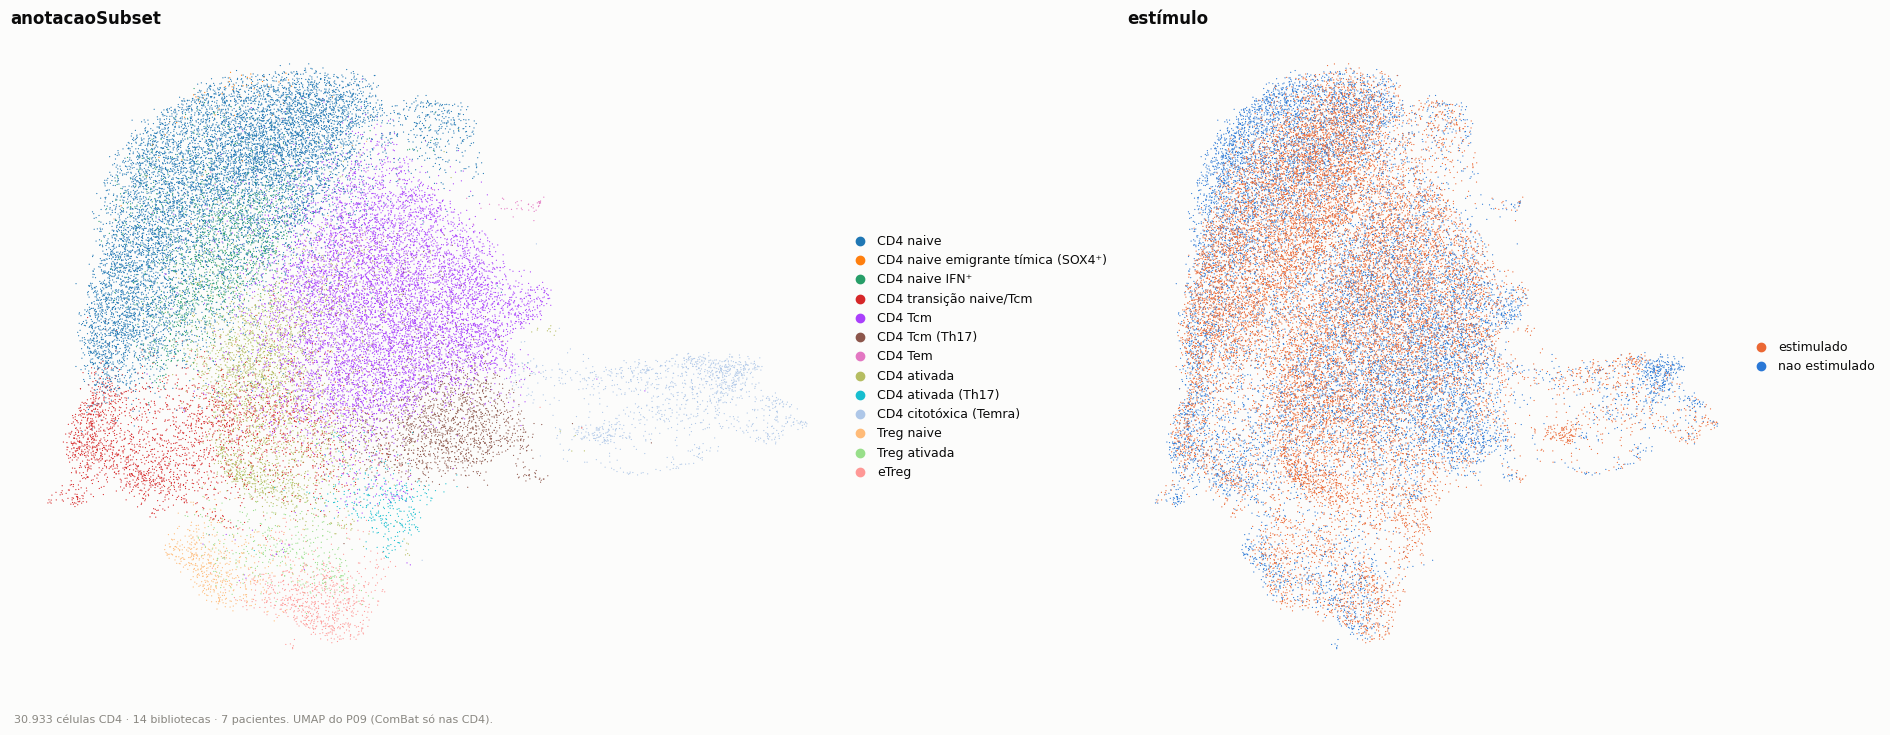

In [3]:
cd4.obs["estimulo"] = pd.Categorical(cd4.obs["estimulo"].astype(str))
cd4.uns["estimulo_colors"] = [plotting.STIMULATION_COLORS["estimulado"] if c == "estimulado"
                              else plotting.STIMULATION_COLORS["nao_estimulado"] for c in cd4.obs["estimulo"].cat.categories]
fig, axes = plt.subplots(1, 2, figsize=(19, 7.2), gridspec_kw={"width_ratios": [1.35, 1]})
sc.pl.umap(cd4, color="anotacaoSubset", ax=axes[0], show=False, frameon=False, size=3, title="anotacaoSubset")
sc.pl.umap(cd4, color="estimulo", ax=axes[1], show=False, frameon=False, size=3, title="estímulo")
plotting.note(fig, f"{F.n(N)} células CD4 · {plotting.N_DESIGN}. UMAP do P09 (ComBat só nas CD4).", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "umap", description="UMAP das CD4 pela anotacaoSubset e pelo estímulo",
                 data=pd.DataFrame({"cell_key": keys, "anotacaoSubset": cd4.obs["anotacaoSubset"].astype(str).to_numpy(),
                                    "estimulo": cd4.obs["estimulo"].astype(str).to_numpy(),
                                    "umap1": cd4.obsm["X_umap"][:, 0], "umap2": cd4.obsm["X_umap"][:, 1]}), data_index=False)
plt.show()

## 2. Marcadores principais (painel curado)

Os genes que definem cada tipo, agrupados por função:
- tamanho do ponto = % de células que detectam o gene (≥ 1 UMI, contagens do SoupX);
- cor = média da lognorm, escalonada por gene entre os tipos (0–1).

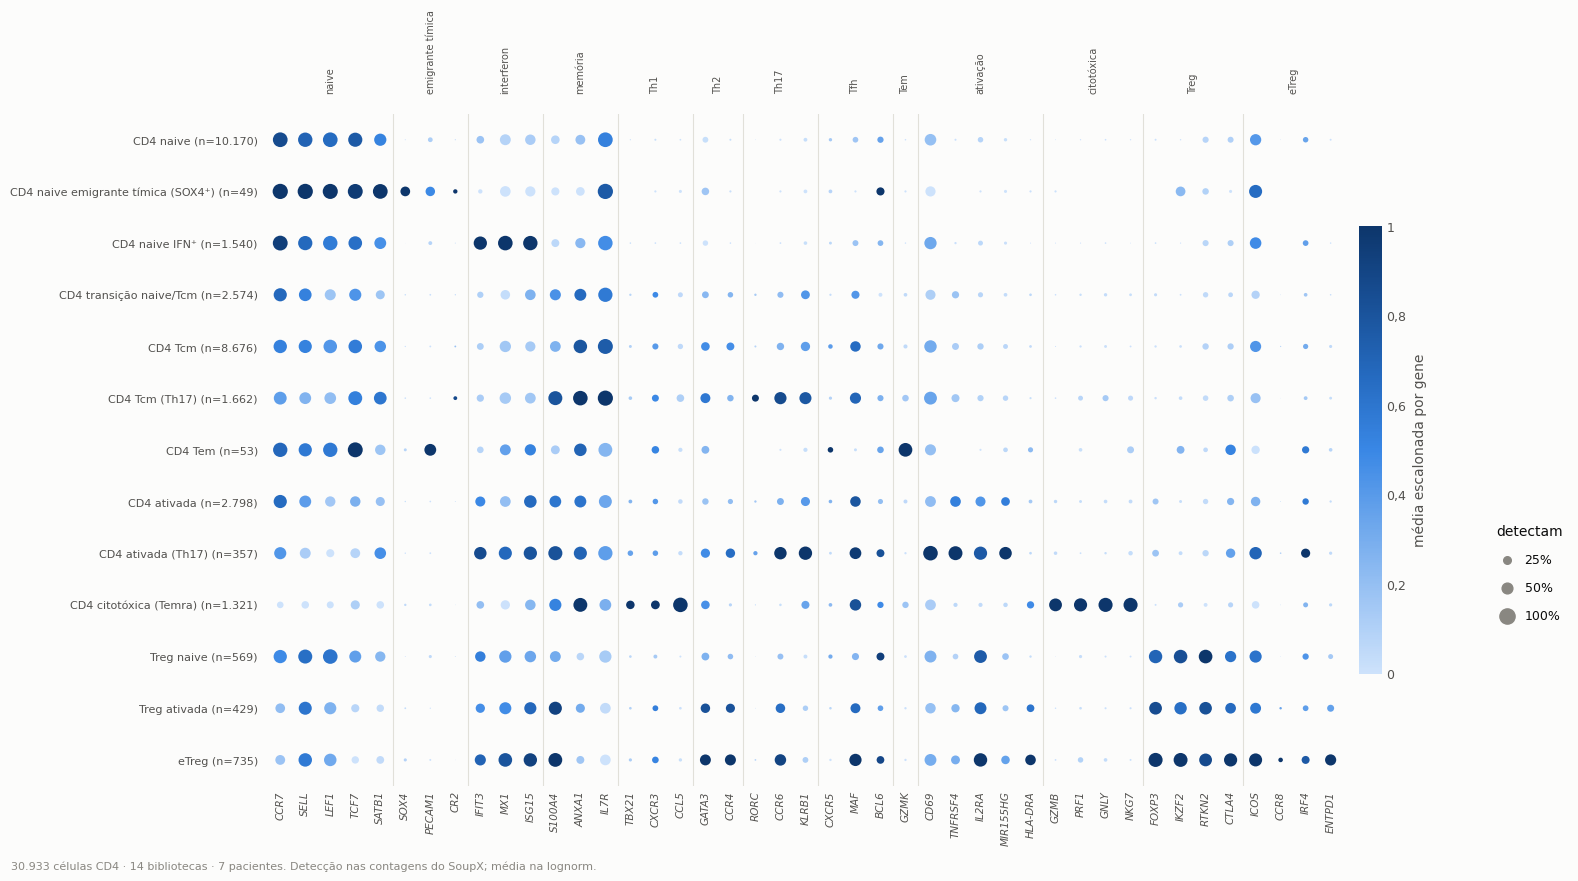

In [4]:
PAINEL = {
    "naive": ["CCR7", "SELL", "LEF1", "TCF7", "SATB1"],
    "emigrante tímica": ["SOX4", "PECAM1", "CR2"],
    "interferon": ["IFIT3", "MX1", "ISG15"],
    "memória": ["S100A4", "ANXA1", "IL7R"],
    "Th1": ["TBX21", "CXCR3", "CCL5"],
    "Th2": ["GATA3", "CCR4"],
    "Th17": ["RORC", "CCR6", "KLRB1"],
    "Tfh": ["CXCR5", "MAF", "BCL6"],
    "Tem": ["GZMK"],
    "ativação": ["CD69", "TNFRSF4", "IL2RA", "MIR155HG", "HLA-DRA"],
    "citotóxica": ["GZMB", "PRF1", "GNLY", "NKG7"],
    "Treg": ["FOXP3", "IKZF2", "RTKN2", "CTLA4"],
    "eTreg": ["ICOS", "CCR8", "IRF4", "ENTPD1"],
}
genes = [g for gs in PAINEL.values() for g in gs if g in cd4.var_names]
frac, mean = an.dot_stats(cd4, cd4.obs["anotacaoSubset"], genes)
grupos_col = [(k, len([g for g in v if g in cd4.var_names])) for k, v in PAINEL.items()]
fig, ax = plt.subplots(figsize=(16, 0.42 * len(TIPOS) + 3.2))
sc_ = an.dotplot(ax, frac, mean, rows=TIPOS, cols=genes, groups_of_cols=grupos_col)
ax.set_yticklabels([f"{t} (n={F.n(n_t[t])})" for t in TIPOS])
cb = fig.colorbar(sc_, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("média escalonada por gene")
plotting._style_colorbar(cb)
for v in (0.25, 0.5, 1.0):
    ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.13, 0.4), frameon=False, labelspacing=1.2)
plotting.note(fig, f"{F.n(N)} células CD4 · {plotting.N_DESIGN}. Detecção nas contagens do SoupX; média na lognorm.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "dotplot_marcadores", description="Marcadores principais por tipo da anotacaoSubset",
                 data=(frac * 100).round(1).reindex(TIPOS).rename_axis("anotacaoSubset").reset_index(), data_index=False)
plt.show()

## 3. Genes diferenciais de cada tipo

Wilcoxon, um tipo contra todos os outros. Para cada tipo, os 5 primeiros genes com:
- log2FC > 0,5;
- p ajustado < 0,05;
- detecção ≥ 20 % no tipo.

Ficam de fora genes ribossomais, mitocondriais e de manutenção.

,tipo,gene,log2FC,p ajustado,detecção no tipo,detecção nos demais
0,CD4 naive,FHIT,3.005,0.0,0.924,0.402
1,CD4 naive,TSHZ2,2.423,0.0,0.944,0.545
2,CD4 naive,IGF1R,2.276,0.0,0.745,0.280
3,CD4 naive,LEF1,1.618,0.0,0.928,0.657
4,CD4 naive,RAPGEF6,1.152,0.0,0.932,0.755
...,...,...,...,...,...,...
60,eTreg,FOXP3,5.184,0.0,0.856,0.060
61,eTreg,IKZF2,5.745,0.0,0.838,0.051
62,eTreg,TIGIT,3.882,0.0,0.814,0.154
63,eTreg,SAMHD1,1.957,0.0,0.962,0.709


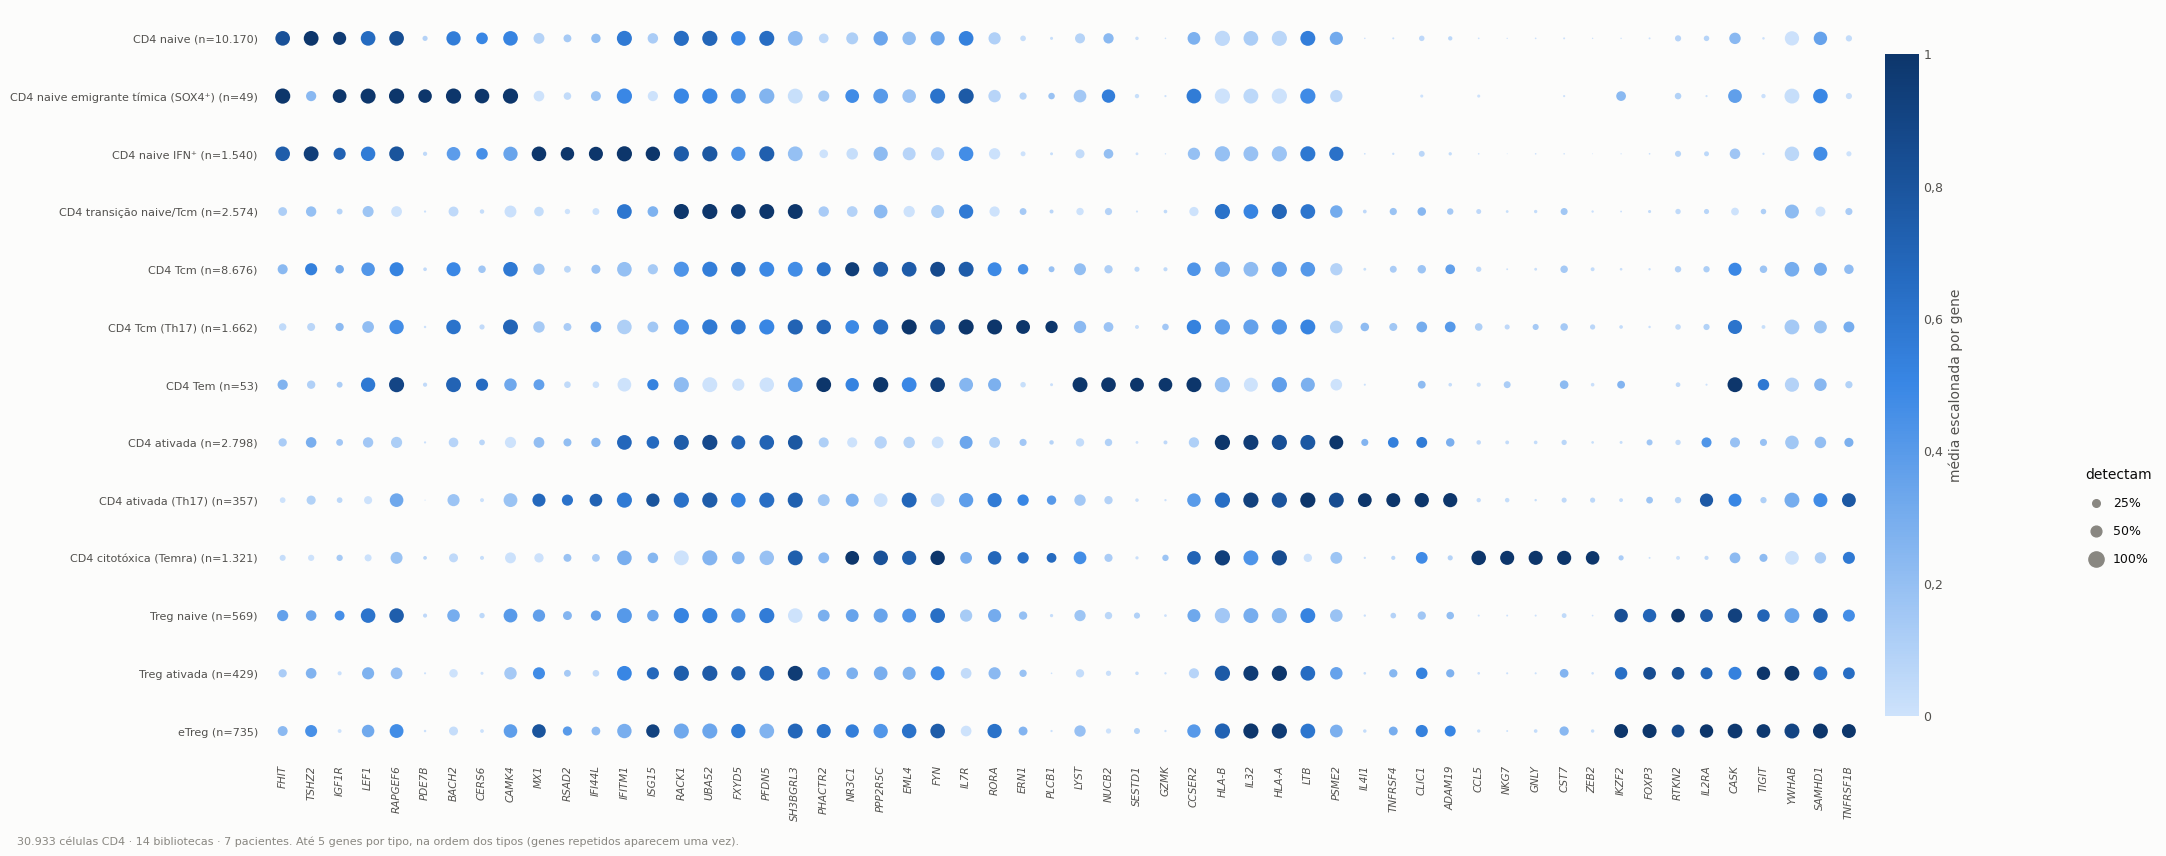

In [5]:
sc.tl.rank_genes_groups(cd4, "anotacaoSubset", method="wilcoxon", pts=True, n_genes=300)
POUCO = r"^(RP[LS]\d|RPLP\d|MT-|ENSG|EEF1|EEF2|TPT1|FAU|NACA|B2M|ACTB|ACTG1|TMSB4X|TMSB10|FTH1|FTL|MALAT1|NEAT1|GAPDH|PFN1|MYL6)"
linhas, top = [], {}
for t in TIPOS:
    df = sc.get.rank_genes_groups_df(cd4, group=t)
    ok = (df["logfoldchanges"] > 0.5) & (df["pvals_adj"] < 0.05) & (df["pct_nz_group"] >= 0.2) & ~df["names"].str.match(POUCO)
    d = df[ok].head(5)
    top[t] = list(d["names"])
    for _, r in d.iterrows():
        linhas.append({"tipo": t, "gene": r["names"], "log2FC": r["logfoldchanges"], "p ajustado": r["pvals_adj"],
                       "detecção no tipo": r["pct_nz_group"], "detecção nos demais": r["pct_nz_reference"]})
deg = pd.DataFrame(linhas)
io.save_table(deg, NB, "genes_diferenciais_top5", index=False, description="5 genes diferenciais por tipo (Wilcoxon, um contra todos)")
display(deg.round(3))

genes_de = list(dict.fromkeys(g for t in TIPOS for g in top[t]))
frac, mean = an.dot_stats(cd4, cd4.obs["anotacaoSubset"], genes_de)
fig, ax = plt.subplots(figsize=(max(12, 0.3 * len(genes_de) + 5), 0.42 * len(TIPOS) + 3.0))
sc_ = an.dotplot(ax, frac, mean, rows=TIPOS, cols=genes_de)
ax.set_yticklabels([f"{t} (n={F.n(n_t[t])})" for t in TIPOS])
cb = fig.colorbar(sc_, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("média escalonada por gene")
plotting._style_colorbar(cb)
for v in (0.25, 0.5, 1.0):
    ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.13, 0.4), frameon=False, labelspacing=1.2)
plotting.note(fig, f"{F.n(N)} células CD4 · {plotting.N_DESIGN}. Até 5 genes por tipo, na ordem dos tipos (genes repetidos aparecem uma vez).",
              y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "dotplot_diferenciais", description="Genes diferenciais por tipo da anotacaoSubset",
                 data=(frac * 100).round(1).reindex(TIPOS).rename_axis("anotacaoSubset").reset_index(), data_index=False)
plt.show()

## 4. Composição por biblioteca

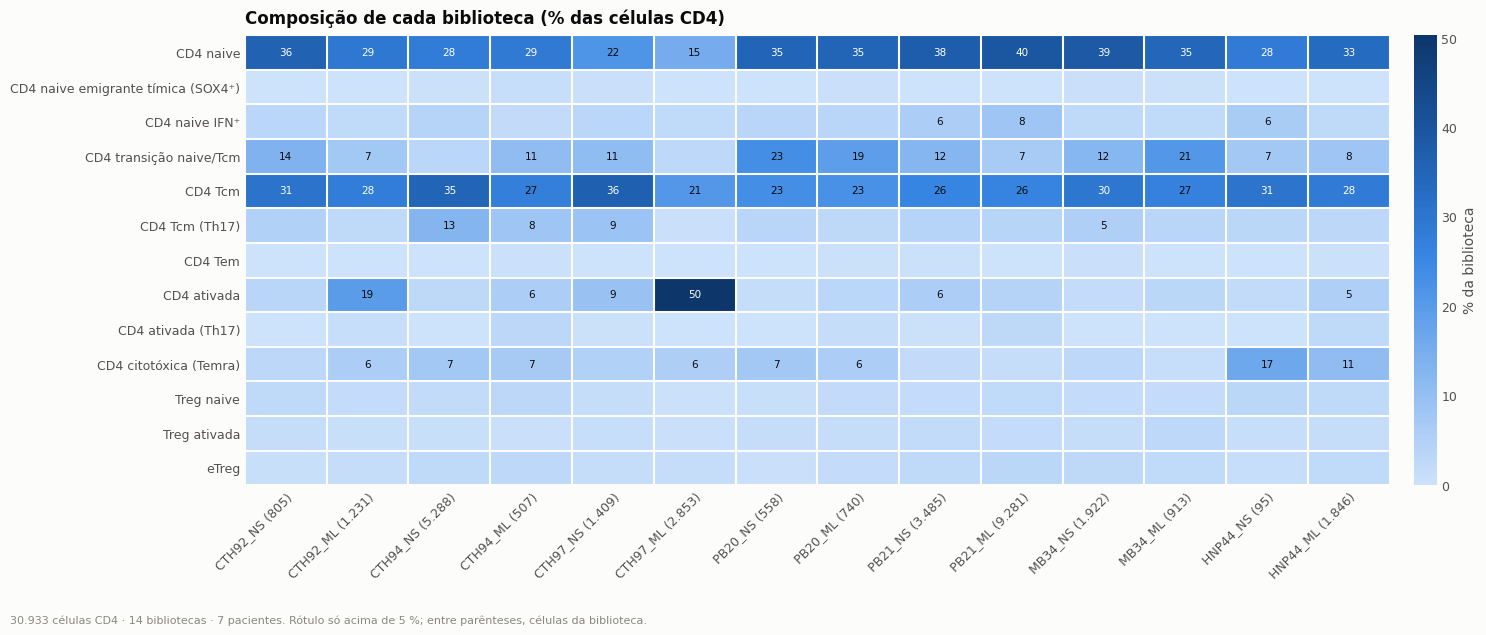

In [6]:
cont = pd.crosstab(cd4.obs["library_id"].astype(str), cd4.obs["anotacaoSubset"]).reindex(index=LIBS, columns=TIPOS)
prop = cont.div(cont.sum(axis=1), axis=0)
io.save_table(cont, NB, "contagens_por_biblioteca", description="Células de cada tipo por biblioteca")
io.save_table(prop, NB, "proporcoes_por_biblioteca", description="Fração de cada tipo por biblioteca")
fig, ax = plt.subplots(figsize=(15, 6.2))
plotting.heatmap(ax, prop.T * 100, vmin=0, cbar_label="% da biblioteca", annotate_above=5, fmt=".0f", xrotation=45)
ax.set_xticklabels([f"{l} ({F.n(cont.loc[l].sum())})" for l in LIBS], rotation=45, ha="right", rotation_mode="anchor")
ax.set_title("Composição de cada biblioteca (% das células CD4)", loc="left")
plotting.note(fig, f"{F.n(N)} células CD4 · {plotting.N_DESIGN}. Rótulo só acima de 5 %; entre parênteses, células da biblioteca.",
              y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "composicao_bibliotecas", description="Fração de cada tipo por biblioteca", data=prop * 100)
plt.show()

## 5. A composição muda com o estímulo ou com o grupo clínico?

Método do P17 da 1ª rodada (`forest_composicao`):
- proporção por biblioteca e CLR com pseudocontagem na escala de contagem;
- filtro de prevalência: ≥ 1 % em ≥ 3 amostras de cada grupo;
- BH entre os tipos.

**Estímulo:** `CLR ~ estímulo + paciente + %MT` nas 14 bibliotecas.

**Grupo clínico:** um ponto por paciente (a média do CLR de NS e ML), em dois contrastes:
- hanseníase (4) × controle (3);
- PB (2) × controle (3).

10 de 13 tipos testáveis no estímulo; fora: ['CD4 Tem', 'CD4 ativada (Th17)', 'CD4 naive emigrante tímica (SOX4⁺)']


,estimate,p_value,FDR,ML > NS (pacientes),ML < NS,p do sinal,% mediana NS,% mediana ML
CD4 naive,-0.011,0.892,0.971,4,3,1.000,34.946,33.044
CD4 naive emigrante tímica (SOX4⁺),NaN,NaN,NaN,3,2,1.000,0.000,0.043
CD4 naive IFN⁺,-0.313,0.186,0.373,2,5,0.453,3.584,2.300
CD4 transição naive/Tcm,-0.100,0.754,0.943,3,4,1.000,12.279,8.288
CD4 Tcm,-0.095,0.175,0.373,1,6,0.125,30.526,26.835
CD4 Tcm (Th17),-0.436,0.047,0.157,0,7,0.016,4.720,2.979
CD4 Tem,NaN,NaN,NaN,3,4,1.000,0.142,0.110
CD4 ativada,0.807,0.042,0.157,6,1,0.125,2.723,5.309
CD4 ativada (Th17),NaN,NaN,NaN,6,1,0.125,0.151,1.216
CD4 citotóxica (Temra),-0.118,0.660,0.943,2,5,0.453,4.826,5.946


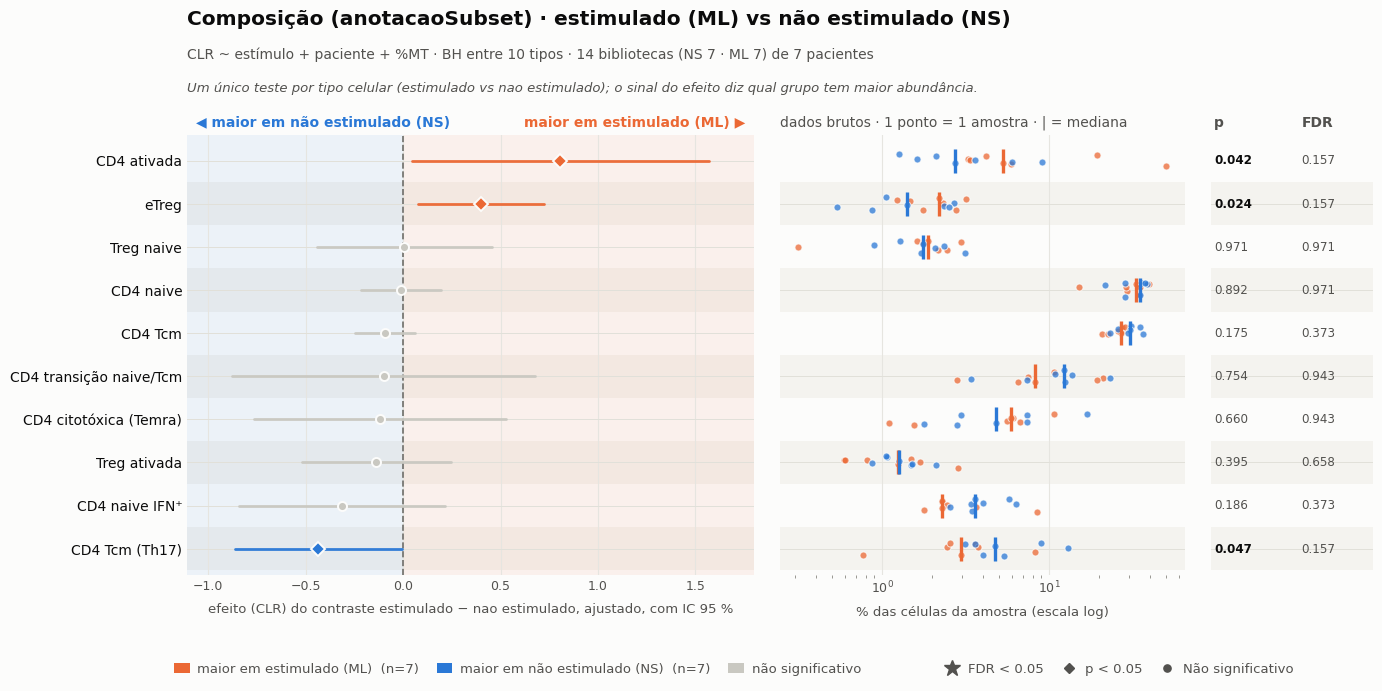

In [7]:
o = cd4.obs
cel = o[["library_id", "patient", "estimulo"]].astype(str).copy()
cel["anotacaoSubset"] = o["anotacaoSubset"].astype(str)
cel["classificacao"] = cel["patient"].map(config.PATIENT_CLASSIFICATION)
cel["doenca"] = np.where(cel["classificacao"] == "controle", "controle", "hanseniase")
smp = o.groupby("library_id", observed=True).agg(pct_mt=("pct_counts_mt", "median"))
smp.index = smp.index.astype(str)
comp = CP.build_composition(cel, "anotacaoSubset", sample_col="library_id", group_col="estimulo",
                            covars=["patient", "classificacao", "doenca"], min_cells=30)
comp["meta"]["pct_mt"] = smp["pct_mt"].reindex(comp["meta"].index).astype(float)
filt = CP.filtro_prevalencia(comp, min_pac=3, min_frac=0.01)
print(f"{len(filt['testaveis'])} de {len(comp['cell_cols'])} tipos testáveis no estímulo; fora: {filt['excluidos']}")
res_est = CP.run_contrast(comp, filt["testaveis"], ordem_grupos=["estimulado", "nao estimulado"], covars=["patient", "pct_mt"],
                          verbose=False)
io.save_table(res_est, NB, "estimulo_ML_vs_NS", index=False, description="CLR ~ estímulo + paciente + %MT, contraste ML − NS")

pm = comp["proportion"].join(comp["meta"][["estimulo", "patient"]])
ns = pm[pm.estimulo == "nao estimulado"].set_index("patient")[comp["cell_cols"]]
ml = pm[pm.estimulo == "estimulado"].set_index("patient")[comp["cell_cols"]].loc[ns.index]
s, dn = (ml > ns).sum(), (ml < ns).sum()
cons = pd.DataFrame({"ML > NS (pacientes)": s, "ML < NS": dn,
                     "p do sinal": [binomtest(int(max(x, y)), int(x + y)).pvalue for x, y in zip(s, dn)],
                     "% mediana NS": 100 * ns.median(), "% mediana ML": 100 * ml.median()})
res_t = res_est.set_index("cell_population")[["estimate", "p_value", "FDR"]].join(cons, how="right").reindex(TIPOS).dropna(how="all")
io.save_table(res_t, NB, "estimulo_resumo", description="ML − NS por tipo: efeito, FDR, consistência entre pacientes e medianas")
display(res_t.round(3))

ROT_LINHA = {t: t for t in TIPOS}
sub_t = (f"CLR ~ estímulo + paciente + %MT · BH entre {len(res_est)} tipos · 14 bibliotecas (NS 7 · ML 7) de 7 pacientes")
fig, _ = FR.forest(res_est, comp, cores_grupo={"nao estimulado": plotting.STIMULATION_COLORS["nao_estimulado"],
                                               "estimulado": plotting.STIMULATION_COLORS["estimulado"]},
                   rotulos={"nao estimulado": "não estimulado (NS)", "estimulado": "estimulado (ML)"},
                   subtitulo=sub_t, rotulos_linha=ROT_LINHA, titulo="Composição (anotacaoSubset) · estimulado (ML) vs não estimulado (NS)")
plotting.savefig(fig, NB, "forest_estimulo", data=res_est, data_index=False, description="Forest do contraste ML − NS (anotacaoSubset)")
plt.show()

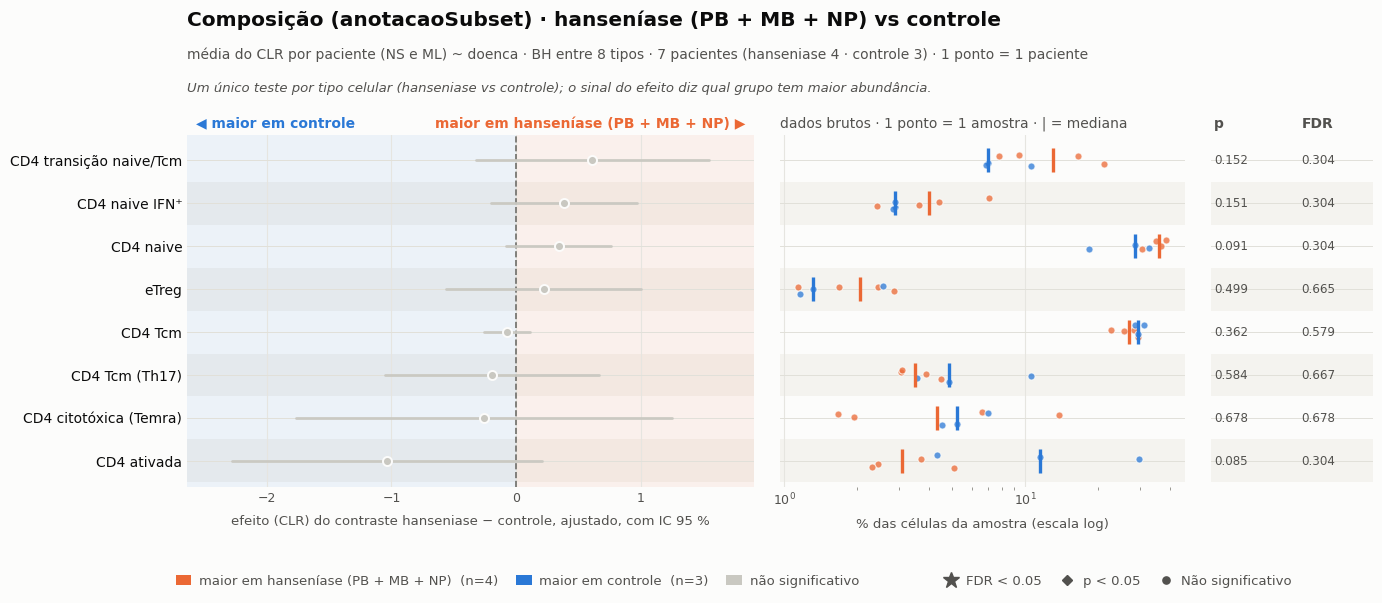

,cell_population,estimate,p_value,FDR,prop_media_g1,prop_media_g2
0,CD4 ativada,-1.0361,0.0855,0.3043,0.0339,0.1519
1,CD4 naive,0.3420,0.0911,0.3043,0.3525,0.2655
2,CD4 naive IFN⁺,0.3851,0.1509,0.3043,0.0438,0.0287
3,CD4 transição naive/Tcm,0.6137,0.1521,0.3043,0.1383,0.0816
4,CD4 Tcm,-0.0721,0.3616,0.5785,0.2661,0.2977
5,eTreg,0.2216,0.4991,0.6654,0.0204,0.0168
6,CD4 Tcm (Th17),-0.1959,0.5836,0.6669,0.0363,0.0635
7,CD4 citotóxica (Temra),-0.2583,0.6779,0.6779,0.0602,0.0559


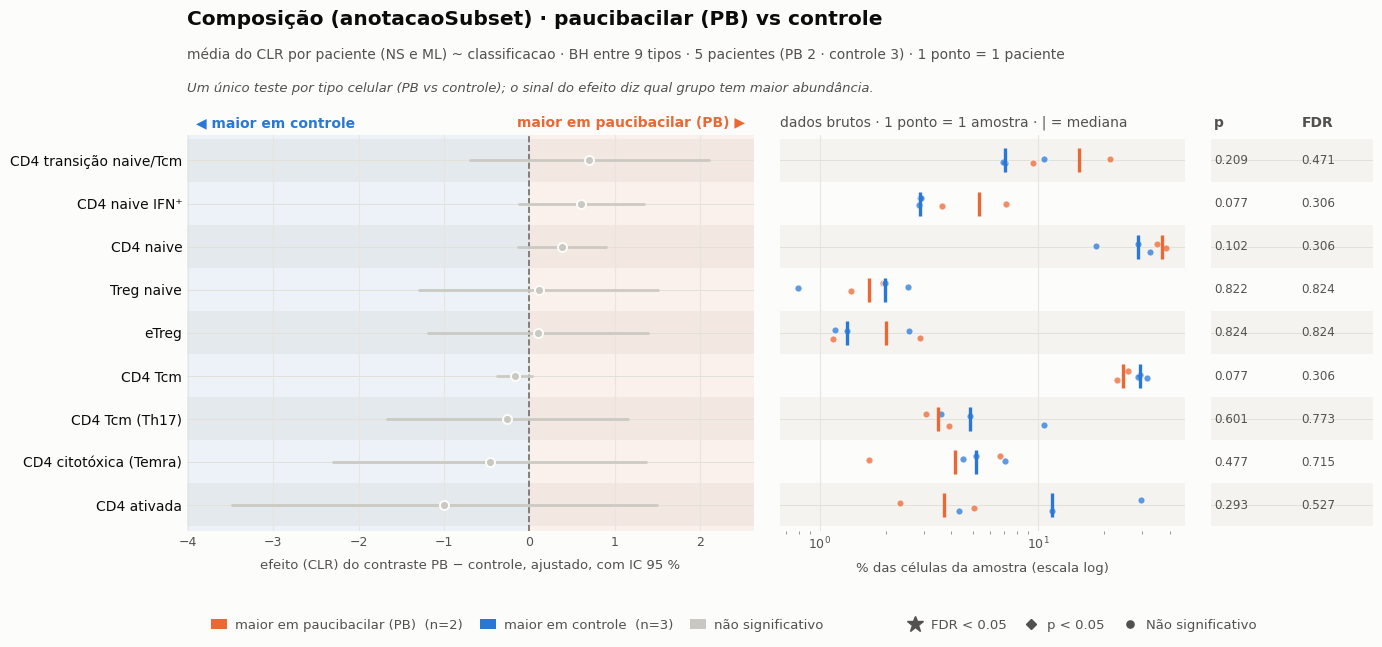

,cell_population,estimate,p_value,FDR,prop_media_g1,prop_media_g2
0,CD4 naive IFN⁺,0.6074,0.0767,0.3063,0.0535,0.0287
1,CD4 Tcm,-0.1703,0.0770,0.3063,0.2436,0.2977
2,CD4 naive,0.3764,0.1021,0.3063,0.3684,0.2655
3,CD4 transição naive/Tcm,0.7003,0.2093,0.4709,0.1543,0.0816
4,CD4 ativada,-0.9952,0.2925,0.5265,0.0370,0.1519
5,CD4 citotóxica (Temra),-0.4673,0.4768,0.7152,0.0416,0.0559
6,CD4 Tcm (Th17),-0.2571,0.6015,0.7733,0.0348,0.0635
7,Treg naive,0.1078,0.8224,0.8243,0.0167,0.0177
8,eTreg,0.0980,0.8243,0.8243,0.0200,0.0168


In [8]:
COR_CLI = {"controle": plotting.CLASSIFICATION_COLORS["controle"], "PB": plotting.CLASSIFICATION_COLORS["PB"],
           "hanseniase": plotting.CLASSIFICATION_COLORS["PB"]}
ROT_CLI = {"controle": "controle", "PB": "paucibacilar (PB)", "hanseniase": "hanseníase (PB + MB + NP)"}
cli = {}
for nome_c, (gcol, ordem) in {"hanseniase_x_controle": ("doenca", ["hanseniase", "controle"]),
                              "PB_x_controle": ("classificacao", ["PB", "controle"])}.items():
    cp = CS.comp_paciente(comp, "patient", gcol, ordem)
    f2 = CS.filtro_prevalencia(cp, min_pac=3, min_frac=0.01)
    res = CS.run_contrast_paciente(comp, cp, f2["testaveis"], ordem)
    cli[nome_c] = res
    io.save_table(res, NB, nome_c, index=False, description=f"{nome_c}: média do CLR por paciente ~ grupo")
    n = cp["meta"][gcol].value_counts()
    sub_c = (f"média do CLR por paciente (NS e ML) ~ {gcol} · BH entre {len(res)} tipos · {res.attrs['n_amostras']} pacientes "
             f"({ordem[0]} {n.get(ordem[0], 0)} · {ordem[1]} {n.get(ordem[1], 0)}) · 1 ponto = 1 paciente")
    fig, _ = FR.forest(res, cp, cores_grupo=COR_CLI, rotulos=ROT_CLI, subtitulo=sub_c, rotulos_linha=ROT_LINHA,
                       titulo=f"Composição (anotacaoSubset) · {ROT_CLI[ordem[0]]} vs {ROT_CLI[ordem[1]]}")
    plotting.savefig(fig, NB, f"forest_{nome_c}", data=res, data_index=False, description=f"Forest {nome_c} (anotacaoSubset)")
    plt.show()
    display(res[["cell_population", "estimate", "p_value", "FDR", "prop_media_g1", "prop_media_g2"]].round(4))

## 6. Interpretação

**Os tipos se sustentam nos marcadores.** Cada linha do dotplot acende no seu bloco:
- **naive:** CCR7, LEF1, TCF7;
- **emigrante tímica:** SOX4, CR2, mais PECAM1 (CD31);
- **IFN⁺:** IFIT3, MX1, ISG15;
- **Tcm (Th17):** RORC, CCR6, KLRB1;
- **CD4 Tem:** GZMK, com CCR7 e TCF7 ainda altos (perfil de memória precoce GZMK⁺);
- **CD4 ativada e ativada (Th17):** TNFRSF4, IL2RA, MIR155HG;
- **citotóxica:** GZMB, PRF1, GNLY, NKG7, com TBX21 e CCL5;
- **Treg:** FOXP3, IKZF2, RTKN2;
- **eTreg:** ICOS, CCR8, IRF4, CD39 (ENTPD1) e HLA-DR.

A Treg ativada aparece com FOXP3 e Helios abaixo da eTreg e GATA3/CCR4 intermediários. Os genes
diferenciais (seção 3) repetem essas assinaturas sem que tenham sido escolhidos de antemão: FHIT,
TSHZ2, IGF1R e LEF1 na naive; FOXP3, IKZF2, TIGIT e TNFRSF1B na eTreg.

**Estímulo (ML × NS, pareado por paciente).** Nenhum tipo passa FDR < 0,05: 10 tipos testados,
e os três menores ficam fora pelo filtro de prevalência. Três têm p < 0,05:
- **CD4 ativada** sobe: mediana de 2,7 % para 5,3 %; ML > NS em 6 dos 7 pacientes;
- **eTreg** sobe: de 1,4 % para 2,2 %; 5 de 7;
- **CD4 Tcm (Th17)** cai: de 4,7 % para 3,0 %; **7 de 7 pacientes** (teste do sinal p = 0,016).

Isso repete a 1ª rodada (ativada ↑, Th17 ↓) e acrescenta a eTreg: o estímulo expande a Treg
efetora, não a Treg como um todo. A Treg naive e a Treg ativada não mudam. A ativada (Th17) sobe
em 6 de 7 pacientes (0,15 % → 1,2 %), mas é rara demais para o filtro.

**Grupos clínicos (um ponto por paciente).** Nada passa FDR, nem p < 0,05.
- **Hanseníase × controle:** a CD4 ativada é menor nos doentes (3,4 % × 15 %; p = 0,086), e a
  naive e a transição naive/Tcm são maiores. É a mesma tendência da 1ª rodada: os controles
  ativam mais.
- **PB × controle:** a naive IFN⁺ é maior no PB (5,4 % × 2,9 %; p = 0,077).

Com 3 a 4 pacientes por grupo, isso é hipótese.

## Problemas encontrados

In [9]:
log.add("INFO", "grupos clínicos", "contrastes clínicos com 3 a 4 pacientes por grupo",
        evidence="hanseníase 4 × controle 3; PB 2 × controle 3; um ponto por paciente",
        impact="poder baixo; resultados exploratórios", recommendation="tratar como hipótese")
show(log.save())

severity,location,problem,evidence,impact,recommendation
INFO,grupos clínicos,contrastes clínicos com 3 a 4 pacientes por grupo,hanseníase 4 × controle 3; PB 2 × controle 3; um ponto por paciente,poder baixo; resultados exploratórios,tratar como hipótese
